In [ ]:
%pip install yfinance

In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

tickers = ["AAPL", "MSFT", "GOOGL"]

prices = yf.download(
    tickers,
    start="2021-01-01",
    end="2026-01-01",
    auto_adjust=True,
    progress=False
)["Close"]

prices = prices.dropna()

print("Dataset shape:", prices.shape)
print("\nFirst five rows:")
display(prices.head())

print("\nMissing values:")
print(prices.isnull().sum())

Dataset shape: (1255, 3)

First five rows:


Ticker,AAPL,GOOGL,MSFT
Date,,,
2021-01-04,125.632507,85.492981,207.565399
2021-01-05,127.185776,86.182419,207.765594
2021-01-06,122.904526,85.332008,202.378387
2021-01-07,127.098427,87.880753,208.137497
2021-01-08,128.195435,89.044182,209.405624



Missing values:
Ticker
AAPL     0
GOOGL    0
MSFT     0
dtype: int64


In [ ]:
# Calculate daily percentage returns
returns = prices.pct_change().dropna()

print("Returns dataset shape:", returns.shape)

print("\nFirst five daily returns:")
display((returns * 100).head().round(3))

print("\nAverage daily return (%):")
display((returns.mean() * 100).round(4))

print("\nDaily return standard deviation (%):")
display((returns.std() * 100).round(4))

Returns dataset shape: (1254, 3)

First five daily returns:


Ticker,AAPL,GOOGL,MSFT
Date,,,
2021-01-05,1.236,0.806,0.096
2021-01-06,-3.366,-0.987,-2.593
2021-01-07,3.412,2.987,2.846
2021-01-08,0.863,1.324,0.609
2021-01-11,-2.325,-2.311,-0.970



Average daily return (%):


,0
Ticker,
AAPL,0.0767
GOOGL,0.1226
MSFT,0.0800



Daily return standard deviation (%):


,0
Ticker,
AAPL,1.7552
GOOGL,1.9620
MSFT,1.6198


In [ ]:
# Annualise daily statistics using 252 trading days
annualised_return = returns.mean() * 252
annualised_volatility = returns.std() * np.sqrt(252)

risk_summary = pd.DataFrame({
    "Average Daily Return (%)": returns.mean() * 100,
    "Annualised Mean Return (%)": annualised_return * 100,
    "Daily Volatility (%)": returns.std() * 100,
    "Annualised Volatility (%)": annualised_volatility * 100
})

display(risk_summary.round(2))

,Average Daily Return (%),Annualised Mean Return (%),Daily Volatility (%),Annualised Volatility (%)
Ticker,,,,
AAPL,0.08,19.32,1.76,27.86
GOOGL,0.12,30.89,1.96,31.15
MSFT,0.08,20.17,1.62,25.71


In [ ]:
# Historical one-day 95% Value at Risk
var_95 = -returns.quantile(0.05)

print("Historical one-day 95% VaR:")
display((var_95 * 100).round(3))

Historical one-day 95% VaR:


,0.05
Ticker,
AAPL,2.804
GOOGL,2.943
MSFT,2.639


In [ ]:
# Calculate cumulative growth of a hypothetical investment
growth = (1 + returns).cumprod()

# Include the initial investment value
initial_value = pd.DataFrame(
    [np.ones(len(returns.columns))],
    columns=returns.columns,
    index=[prices.index[0]]
)

growth = pd.concat([initial_value, growth]).sort_index()

# Calculate running peak and drawdown
running_peak = growth.cummax()
drawdown = (growth / running_peak) - 1

# Maximum drawdown for each stock
max_drawdown = drawdown.min() * 100

print("Maximum Drawdown (%):")
display(max_drawdown.round(2))

Maximum Drawdown (%):


,0
Ticker,
AAPL,-33.36
GOOGL,-44.32
MSFT,-37.15


In [ ]:
# Correlation between daily stock returns
correlation = returns.corr()

print("Daily Return Correlation Matrix:")
display(correlation.round(3))

Daily Return Correlation Matrix:


Ticker,AAPL,GOOGL,MSFT
Ticker,,,
AAPL,1.000,0.579,0.634
GOOGL,0.579,1.000,0.644
MSFT,0.634,0.644,1.000


In [ ]:
import numpy as np
import pandas as pd

# Equal weight for each stock
weights = np.array([1/3, 1/3, 1/3])

# Daily portfolio returns
portfolio_returns = returns @ weights

# Annualised risk and return estimates
annual_return = portfolio_returns.mean() * 252 * 100
annual_volatility = portfolio_returns.std() * np.sqrt(252) * 100

# Historical one-day 95% VaR
portfolio_var_95 = -portfolio_returns.quantile(0.05) * 100

# Maximum drawdown
portfolio_growth = (1 + portfolio_returns).cumprod()
portfolio_growth = pd.concat([
    pd.Series([1.0], index=[prices.index[0]]),
    portfolio_growth
]).sort_index()

portfolio_drawdown = (
    portfolio_growth / portfolio_growth.cummax()
) - 1

portfolio_max_drawdown = portfolio_drawdown.min() * 100

# Display portfolio metrics
portfolio_metrics = pd.Series({
    "Annualised Mean Return (%)": annual_return,
    "Annualised Volatility (%)": annual_volatility,
    "Historical 1-Day 95% VaR (%)": portfolio_var_95,
    "Maximum Drawdown (%)": portfolio_max_drawdown
})

display(portfolio_metrics.round(2))

,0
Annualised Mean Return (%),23.46
Annualised Volatility (%),24.39
Historical 1-Day 95% VaR (%),2.51
Maximum Drawdown (%),-35.12


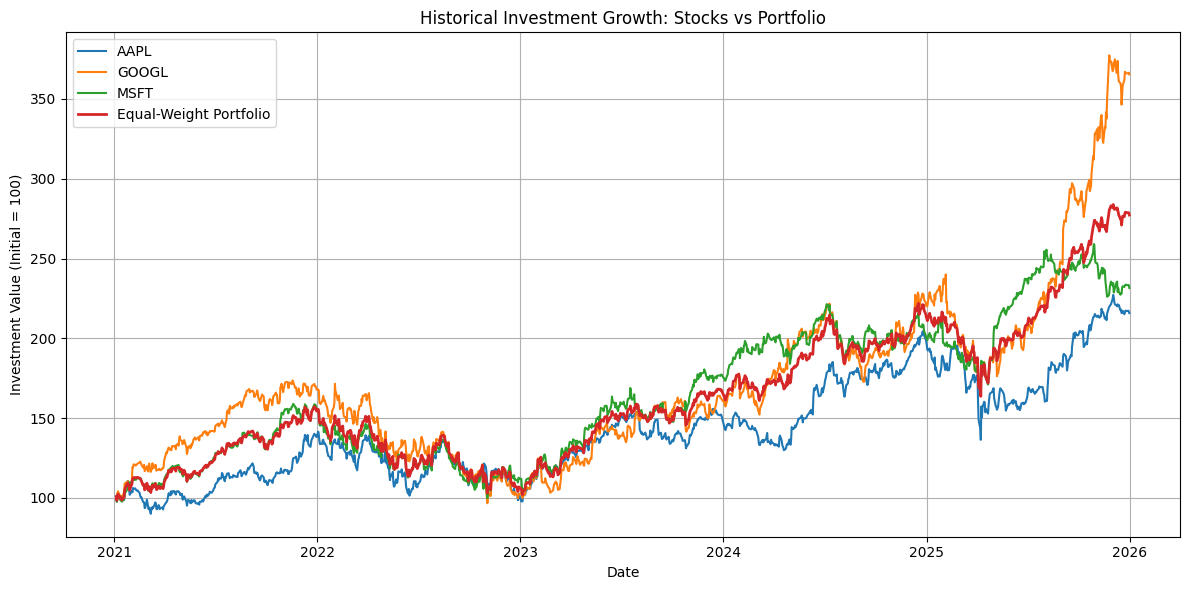

In [ ]:
import matplotlib.pyplot as plt

# Normalise each investment to 100 at the beginning
stock_growth = (1 + returns).cumprod()
stock_growth = stock_growth * 100

# Equal-weight portfolio growth
portfolio_growth = (1 + portfolio_returns).cumprod() * 100

# Plot the performance
plt.figure(figsize=(12, 6))

for ticker in stock_growth.columns:
    plt.plot(stock_growth.index, stock_growth[ticker], label=ticker)

plt.plot(
    portfolio_growth.index,
    portfolio_growth,
    label="Equal-Weight Portfolio",
    linewidth=2
)

plt.title("Historical Investment Growth: Stocks vs Portfolio")
plt.xlabel("Date")
plt.ylabel("Investment Value (Initial = 100)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

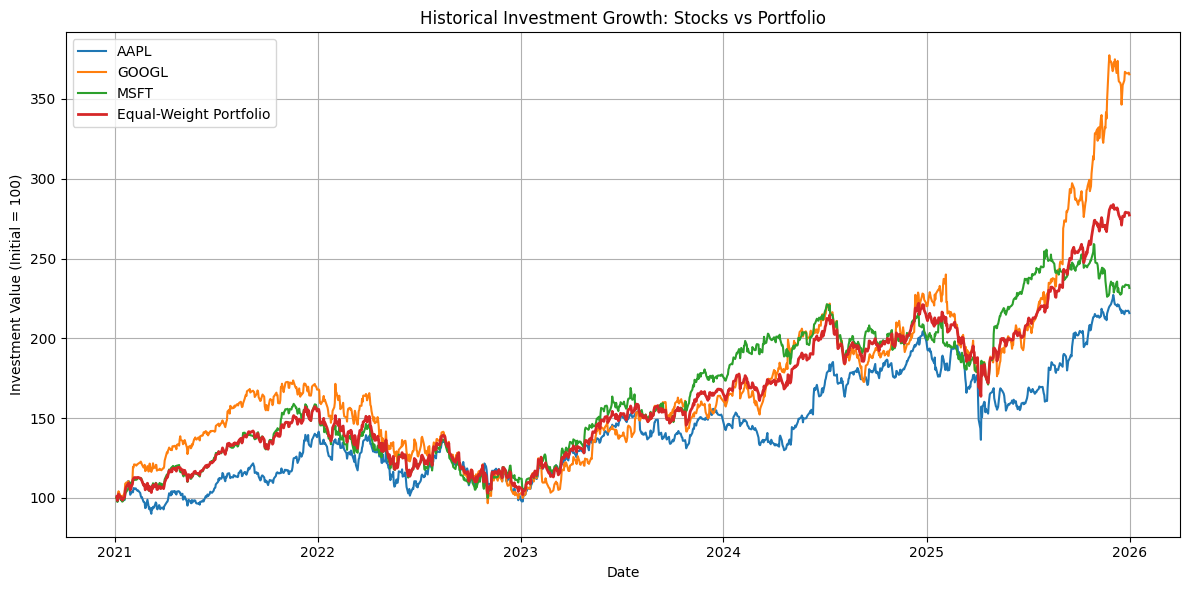

In [ ]:
# Align all investments to the same initial date and value
growth = prices / prices.iloc[0] * 100

# Equal-weight portfolio value, rebalanced daily to equal weights
portfolio_growth = (
    (1 + portfolio_returns).cumprod() * 100
)

plt.figure(figsize=(12, 6))

for ticker in growth.columns:
    plt.plot(growth.index, growth[ticker], label=ticker)

plt.plot(
    portfolio_growth.index,
    portfolio_growth,
    label="Equal-Weight Portfolio",
    linewidth=2
)

plt.title("Historical Investment Growth: Stocks vs Portfolio")
plt.xlabel("Date")
plt.ylabel("Investment Value (Initial = 100)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
# Assumed annual risk-free rate: 4%
risk_free_rate = 0.04

# Annualised arithmetic mean returns
annual_returns = returns.mean() * 252

# Annualised volatility
annual_volatility = returns.std() * np.sqrt(252)

# Annualised Sharpe ratios
sharpe_ratios = (
    annual_returns - risk_free_rate
) / annual_volatility

# Portfolio Sharpe ratio
portfolio_sharpe = (
    portfolio_returns.mean() * 252 - risk_free_rate
) / (
    portfolio_returns.std() * np.sqrt(252)
)

results = pd.DataFrame({
    "Annualised Return (%)": annual_returns * 100,
    "Annualised Volatility (%)": annual_volatility * 100,
    "Sharpe Ratio": sharpe_ratios
})

results.loc["Equal-Weight Portfolio"] = [
    portfolio_returns.mean() * 252 * 100,
    portfolio_returns.std() * np.sqrt(252) * 100,
    portfolio_sharpe
]

display(results.round(3))

,Annualised Return (%),Annualised Volatility (%),Sharpe Ratio
Ticker,,,
AAPL,19.323,27.863,0.550
GOOGL,30.893,31.146,0.863
MSFT,20.173,25.714,0.629
Equal-Weight Portfolio,23.463,24.386,0.798


In [ ]:
import yfinance as yf
import pandas as pd
import numpy as np

# Download S&P 500 adjusted closing prices
benchmark_prices = yf.download(
    "^GSPC",
    start="2021-01-01",
    end="2026-01-01",
    auto_adjust=True,
    progress=False
)["Close"]

# Handle yfinance's possible one-column DataFrame output
benchmark_prices = benchmark_prices.squeeze().dropna()

# Calculate daily benchmark returns
benchmark_returns = benchmark_prices.pct_change().dropna()

print("Benchmark observations:", len(benchmark_returns))
print("\nFirst five daily returns:")
display(benchmark_returns.head())

Benchmark observations: 1254

First five daily returns:


,^GSPC
Date,
2021-01-05,0.007083
2021-01-06,0.005710
2021-01-07,0.014847
2021-01-08,0.005492
2021-01-11,-0.006555


In [ ]:
# Align dates so both series cover the same observations
comparison = pd.concat(
    [
        portfolio_returns.rename("Portfolio"),
        benchmark_returns.rename("S&P 500")
    ],
    axis=1
).dropna()

# Calculate annualised metrics over the common period
summary = pd.DataFrame({
    "Annualised Return (%)": comparison.mean() * 252 * 100,
    "Annualised Volatility (%)": comparison.std() * np.sqrt(252) * 100,
    "Historical 1-Day 95% VaR (%)":
        -comparison.quantile(0.05) * 100
})

display(summary.round(3))

,Annualised Return (%),Annualised Volatility (%),Historical 1-Day 95% VaR (%)
Portfolio,23.463,24.386,2.512
S&P 500,13.799,16.958,1.646


In [ ]:
# Use the same dates for portfolio and benchmark
comparison = pd.concat(
    [
        portfolio_returns.rename("Portfolio"),
        benchmark_returns.rename("Market")
    ],
    axis=1
).dropna()

# Annual risk-free rate assumption
risk_free_rate = 0.04
daily_rf = risk_free_rate / 252

# Beta = covariance with market / market variance
covariance = comparison["Portfolio"].cov(comparison["Market"])
market_variance = comparison["Market"].var()

beta = covariance / market_variance

# Annualised arithmetic returns over the common period
portfolio_return = comparison["Portfolio"].mean() * 252
market_return = comparison["Market"].mean() * 252

# CAPM-style annualised alpha
alpha = (
    portfolio_return
    - (
        risk_free_rate
        + beta * (market_return - risk_free_rate)
    )
)

print(f"Portfolio Beta: {beta:.3f}")
print(f"Annualised CAPM Alpha: {alpha * 100:.2f}%")

Portfolio Beta: 1.222
Annualised CAPM Alpha: 7.48%
